<a href="https://colab.research.google.com/github/tishasetia13/planet-or-not/blob/main/planet_or_not_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### DATA

In [1]:
!pip install lightkurve

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 851.9 kB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.1/261.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 43.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 43.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.2/336.2 kB 18.2 MB/s eta 0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11427 sha256=438ba9ff0da8ba67662bc92e4f92345d77426496975e20416a076fd24e0d9ad4
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/2

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


SearchResult containing 4 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 01 2009 Kepler    1800 kplr006922244      0.0
  1 Kepler Quarter 02 2009 Kepler    1800 kplr006922244      0.0
  2 Kepler Quarter 03 2009 Kepler    1800 kplr006922244      0.0
  3 Kepler Quarter 04 2010 Kepler    1800 kplr006922244      0.0


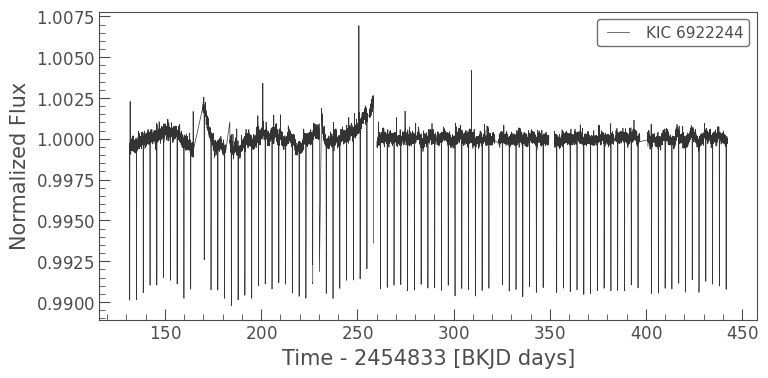

In [2]:
import lightkurve as lk
import matplotlib.pyplot as plt

search_result = lk.search_lightcurve("Kepler-8", author="Kepler", cadence="long", quarter=[1, 2, 3, 4])
print(search_result)

lc_collection = search_result.download_all()

lc = lc_collection.stitch()

lc.plot()
plt.show()

In [4]:
import pandas as pd

CSV_PATH = 'koi_cumulative.csv'

def load_koi_table(path):
  return pd.read_csv(path, comment='#')

koi = load_koi_table(CSV_PATH)

print("Rows and columns:", koi.shape)
print(koi["koi_disposition"].value_counts())

print(list(koi.columns))

Rows and columns: (9564, 141)
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64
['rowid', 'kepid', 'kepoi_name', 'kepler_name', 'koi_disposition', 'koi_vet_stat', 'koi_vet_date', 'koi_pdisposition', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_disp_prov', 'koi_comment', 'koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_time0', 'koi_time0_err1', 'koi_time0_err2', 'koi_eccen', 'koi_eccen_err1', 'koi_eccen_err2', 'koi_longp', 'koi_longp_err1', 'koi_longp_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_ingress', 'koi_ingress_err1', 'koi_ingress_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_ror', 'koi_ror_err1', 'koi_ror_err2', 'koi_srho', 'koi_srho_err1', 'koi_srho_err2', 'koi_fittype', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_sma'

In [5]:
def missing_report(df):
  counts = df.isna().sum()
  percent = (counts / len(df) * 100).round(1)
  report = pd.DataFrame({'missing': counts, 'percent': percent})
  return report.sort_values("missing", ascending=False)

print(missing_report(koi).head(25))

wanted = ["kepid", "kepoi_name", "koi_disposition", "koi_period",
          "koi_time0bk", "koi_depth", "koi_prad", "koi_model_snr"]

def check_columns(df, names):
  for name in names:
    print(f"{name:18} found: {name in df.columns}")

check_columns(koi, wanted)

                  missing  percent
koi_incl_err1        9564    100.0
koi_sma_err2         9564    100.0
koi_sma_err1         9564    100.0
koi_teq_err1         9564    100.0
koi_teq_err2         9564    100.0
koi_longp_err2       9564    100.0
koi_ingress          9564    100.0
koi_ingress_err2     9564    100.0
koi_ingress_err1     9564    100.0
koi_longp_err1       9564    100.0
koi_longp            9564    100.0
koi_eccen_err2       9564    100.0
koi_eccen_err1       9564    100.0
koi_sage_err1        9564    100.0
koi_sage_err2        9564    100.0
koi_sage             9564    100.0
koi_model_dof        9564    100.0
koi_model_chisq      9564    100.0
koi_incl_err2        9564    100.0
kepler_name          6816     71.3
koi_bin_oedp_sig     1510     15.8
koi_score            1510     15.8
koi_comment          1209     12.6
koi_max_sngle_ev     1142     11.9
koi_quarters         1142     11.9
kepid              found: True
kepoi_name         found: True
koi_disposition    found: Tr

In [6]:
# test cell
def list_columns(df):
    """Print one line per column: position, name, data type, number of empty cells."""
    for position, name in enumerate(df.columns):
        empty = df[name].isna().sum()                 # count of empty cells in this column
        print(f"{position:3d}  {name:28s} {str(df[name].dtype):9s} empty={empty}")

list_columns(koi)

  0  rowid                        int64     empty=0
  1  kepid                        int64     empty=0
  2  kepoi_name                   object    empty=0
  3  kepler_name                  object    empty=6816
  4  koi_disposition              object    empty=0
  5  koi_vet_stat                 object    empty=0
  6  koi_vet_date                 object    empty=0
  7  koi_pdisposition             object    empty=0
  8  koi_score                    float64   empty=1510
  9  koi_fpflag_nt                int64     empty=0
 10  koi_fpflag_ss                int64     empty=0
 11  koi_fpflag_co                int64     empty=0
 12  koi_fpflag_ec                int64     empty=0
 13  koi_disp_prov                object    empty=0
 14  koi_comment                  object    empty=1209
 15  koi_period                   float64   empty=0
 16  koi_period_err1              float64   empty=454
 17  koi_period_err2              float64   empty=454
 18  koi_time0bk                  float64   empty=0

In [7]:
def labeled_only(df):
    """Return a copy of the table containing only CONFIRMED and FALSE POSITIVE rows."""
    keep = df["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])
    return df[keep].copy()

labeled = labeled_only(koi)
print("Labeled rows:", len(labeled))

def leak_report(df):
    """Print three tables showing how the suspect columns line up with the label."""
    label = df["koi_disposition"]

    print("1) Is kepler_name filled?")
    print(pd.crosstab(label, df["kepler_name"].notna()), "\n")

    print("2) koi_pdisposition (the Kepler pipeline's own verdict)")
    print(pd.crosstab(label, df["koi_pdisposition"]), "\n")

    print("3) Average koi_score and share of rows flagged, per label")
    suspects = ["koi_score", "koi_fpflag_nt", "koi_fpflag_ss",
                "koi_fpflag_co", "koi_fpflag_ec"]
    print(df.groupby("koi_disposition")[suspects].mean().round(3))

leak_report(labeled)

Labeled rows: 7587
1) Is kepler_name filled?
kepler_name      False  True 
koi_disposition              
CONFIRMED            2   2746
FALSE POSITIVE    4837      2 

2) koi_pdisposition (the Kepler pipeline's own verdict)
koi_pdisposition  CANDIDATE  FALSE POSITIVE
koi_disposition                            
CONFIRMED              2739               9
FALSE POSITIVE            1            4838 

3) Average koi_score and share of rows flagged, per label
                 koi_score  koi_fpflag_nt  koi_fpflag_ss  koi_fpflag_co  \
koi_disposition                                                           
CONFIRMED            0.960          0.170          0.005           0.00   
FALSE POSITIVE       0.038          0.315          0.457           0.39   

                 koi_fpflag_ec  
koi_disposition                 
CONFIRMED                0.000  
FALSE POSITIVE           0.237  


In [8]:
# important cell that is doing some modifications to the data that we are going to feed to the model. what we are doing here is - dropping and selecting the columns and inputs that goes into the model.
answer_key_cols = [
    "kepler_name", "koi_pdisposition", "koi_score",
    "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec",
    "koi_comment", "koi_vet_stat", "koi_vet_date",
    "koi_datalink_dvr", "koi_datalink_dvs",
]

empty_cols = [c for c in koi.columns if koi[c].isna().all()]
print("Empty columns:", len(empty_cols))        # expect 19

koi_small = koi.drop(columns=answer_key_cols + empty_cols)
print("Before:", koi.shape, " After:", koi_small.shape)    # expect 141 -> 110 columns

Empty columns: 19
Before: (9564, 141)  After: (9564, 110)


In [9]:
# same function as the upper one, but for different columns

err_cols = [c for c in koi_small.columns if c.endswith(("_err", "_err1", "_err2"))]
print("Uncertainty columns:", len(err_cols))

koi_small = koi_small.drop(columns=err_cols)
print("Now:", koi_small.shape)

Uncertainty columns: 44
Now: (9564, 66)


In [10]:
# same function as the upper one, but for different columns

paperwork_cols = [
    "koi_disp_prov", "koi_parm_prov", "koi_tce_delivname", "koi_tce_plnt_num",
    "koi_fittype", "koi_limbdark_mod", "koi_trans_mod", "koi_sparprov",
    "koi_quarters", "koi_bin_oedp_sig", "koi_count",
]

koi_small = koi_small.drop(columns=paperwork_cols)
print("Now:", koi_small.shape)

Now: (9564, 55)


In [11]:
pixel_cols = [c for c in koi_small.columns
              if c.startswith(("koi_fwm_", "koi_dicco_", "koi_dikco_"))]
print("Picture columns:", len(pixel_cols))

koi_small = koi_small.drop(columns=pixel_cols)
print("Now:", koi_small.shape)

Picture columns: 13
Now: (9564, 42)


In [12]:
# test cell

# Stage 1: name the columns that have special jobs (they are not model inputs)
id_cols   = ["rowid", "kepid", "kepoi_name"]    # say which object each row is
label_col = "koi_disposition"                   # the answer we want to predict
fold_cols = ["koi_time0bk", "koi_time0"]        # needed later to fold light curves

# Stage 2: everything else is a candidate model input
special = id_cols + [label_col] + fold_cols
feature_cols = [c for c in koi_small.columns if c not in special]

print("Special columns:", len(special))         # expect 6
print("Input columns:", len(feature_cols))      # expect 36
print(feature_cols)

# Stage 3: safety check that no answer-key column is still in the table
leaked = set(answer_key_cols) & set(koi_small.columns)
print("Answer-key columns still present:", leaked)   # expect set()

Special columns: 6
Input columns: 36
['koi_period', 'koi_eccen', 'koi_impact', 'koi_duration', 'koi_depth', 'koi_ror', 'koi_srho', 'koi_prad', 'koi_sma', 'koi_incl', 'koi_teq', 'koi_insol', 'koi_dor', 'koi_ldm_coeff4', 'koi_ldm_coeff3', 'koi_ldm_coeff2', 'koi_ldm_coeff1', 'koi_max_sngle_ev', 'koi_max_mult_ev', 'koi_model_snr', 'koi_num_transits', 'koi_steff', 'koi_slogg', 'koi_smet', 'koi_srad', 'koi_smass', 'ra', 'dec', 'koi_kepmag', 'koi_gmag', 'koi_rmag', 'koi_imag', 'koi_zmag', 'koi_jmag', 'koi_hmag', 'koi_kmag']
Answer-key columns still present: set()


In [13]:
# cell where we select the rows that goes into the model, just like we did for the columns

# Stage 1: mark each row True if its label is CONFIRMED or FALSE POSITIVE
keep_rows = koi_small[label_col].isin(["CONFIRMED", "FALSE POSITIVE"])

# Stage 2: keep only the marked rows, as a separate copy called clean
clean = koi_small[keep_rows].copy()
print("Clean table:", clean.shape)                  # expect (7587, 42)

# Stage 3: count each label and the share that are real planets
print(clean[label_col].value_counts())              # expect FALSE POSITIVE 4839, CONFIRMED 2748
print("Share confirmed:", round((clean[label_col] == "CONFIRMED").mean(), 3))   # expect 0.362

Clean table: (7587, 42)
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
Name: count, dtype: int64
Share confirmed: 0.362


In [14]:
# test cell

# Stage 1: count how many different stars (kepid values) appear in the clean table
n_stars = clean["kepid"].nunique()
print("Rows:", len(clean), "  Stars:", n_stars)

# Stage 2: count the rows of each star, then see how common each count is
rows_per_star = clean.groupby("kepid").size()
print(rows_per_star.value_counts().sort_index())

Rows: 7587   Stars: 6641
1    5990
2     450
3     133
4      46
5      19
6       2
7       1
Name: count, dtype: int64


In [15]:
# splitting our dataset into train, val and test. we are splitting by star and not by row.

# Stage 1: set up the shuffle
import numpy as np

SEED = 42    # fixed random seed, so the shuffle comes out the same every time

def assign_star_splits(star_ids, seed):
    """Shuffle the stars and deal them into train (70%), validation (15%) and test (15%)."""
    rng = np.random.default_rng(seed)            # random number generator, started from the seed
    shuffled = rng.permutation(star_ids)         # the same stars, in a random order
    n = len(shuffled)
    train_end = int(0.70 * n)                    # cut point after the first 70%
    val_end = int(0.85 * n)                      # cut point after the next 15%
    return {
        "train": shuffled[:train_end],
        "val":   shuffled[train_end:val_end],
        "test":  shuffled[val_end:],
    }

# Stage 2: deal out the stars (each star appears once in this list)
star_ids = clean["kepid"].unique()
star_splits = assign_star_splits(star_ids, SEED)

# Stage 3: give every row the pile of its star
clean["split"] = "train"                                          # start by marking everyone as train
clean.loc[clean["kepid"].isin(star_splits["val"]), "split"] = "val"     # rows of validation stars
clean.loc[clean["kepid"].isin(star_splits["test"]), "split"] = "test"   # rows of test stars

# Stage 4: quick count of stars and rows in each pile
print("Stars per pile:", {name: len(stars) for name, stars in star_splits.items()})
print(clean["split"].value_counts())

Stars per pile: {'train': 4648, 'val': 996, 'test': 997}
split
train    5305
test     1150
val      1132
Name: count, dtype: int64


In [16]:
# inspecting and checking and confirming the splitted data in each set, train, val and test.

# Stage 1: check that no star appears in more than one pile
def count_piles_per_star(df):
    """Return, for each star, how many different piles its rows are in."""
    return df.groupby("kepid")["split"].nunique()

piles_per_star = count_piles_per_star(clean)
print("Stars in more than one pile:", (piles_per_star > 1).sum())     # expect 0

# Stage 2: check every star was dealt exactly once
dealt = sum(len(stars) for stars in star_splits.values())
print("Stars dealt:", dealt, " Stars in table:", n_stars)             # expect 6641 and 6641

# Stage 3: check the planet share and label counts in each pile
planet_share = (clean["koi_disposition"] == "CONFIRMED").groupby(clean["split"]).mean()
print((planet_share * 100).round(1))                                  # whole table is 36.2
print(pd.crosstab(clean["split"], clean["koi_disposition"]))

Stars in more than one pile: 0
Stars dealt: 6641  Stars in table: 6641
split
test     37.9
train    35.8
val      36.3
Name: koi_disposition, dtype: float64
koi_disposition  CONFIRMED  FALSE POSITIVE
split                                     
test                   436             714
train                 1901            3404
val                    411             721


In [17]:
# making the final split tables

# Stage 1: make one table per pile, using the split column
train_df = clean[clean["split"] == "train"].copy()
val_df   = clean[clean["split"] == "val"].copy()
test_df  = clean[clean["split"] == "test"].copy()     # made, but we do NOT look at it
print(len(train_df), len(val_df), len(test_df))        # expect 5305 1132 1150

# Stage 2: view 1, the first 10 rows (ids, the answer, and the first 8 inputs)
display(train_df[id_cols + [label_col] + feature_cols[:8]].head(10))

# Stage 3: view 2, a summary of every input column
display(train_df[feature_cols].describe().T.round(2))

5305 1132 1150


,rowid,kepid,kepoi_name,koi_disposition,koi_period,koi_eccen,koi_impact,koi_duration,koi_depth,koi_ror,koi_srho,koi_prad
3,4,10848459,K00754.01,FALSE POSITIVE,1.736952,0.0,1.276,2.40641,8079.2,0.387394,0.22080,33.46
5,6,10872983,K00756.01,CONFIRMED,11.094321,0.0,0.538,4.59450,1517.5,0.036779,0.67324,3.90
6,7,10872983,K00756.02,CONFIRMED,4.134435,0.0,0.762,3.14020,686.0,0.026133,0.37377,2.77
7,8,10872983,K00756.03,CONFIRMED,2.566589,0.0,0.755,2.42900,226.5,0.014983,0.48909,1.59
8,9,6721123,K00114.01,FALSE POSITIVE,7.361790,0.0,1.169,5.02200,233.7,0.183387,0.00485,39.21
12,13,6922244,K00010.01,CONFIRMED,3.522498,0.0,0.631,3.19843,9145.7,0.092086,0.65374,14.59
13,14,10984090,K00112.02,CONFIRMED,3.709214,0.0,0.051,2.63020,131.1,0.010424,1.77451,1.16
15,16,10464078,K00743.01,FALSE POSITIVE,19.403938,0.0,0.804,12.21550,8918.7,0.096729,0.03785,7.18
16,17,10480982,K00744.01,FALSE POSITIVE,19.221389,0.0,1.065,4.79843,74284.0,0.476633,1.57359,49.29
17,18,10485250,K00745.01,FALSE POSITIVE,16.469838,0.0,0.292,9.43780,10479.0,0.092509,0.19353,7.94


,count,mean,std,min,25%,50%,75%,max
koi_period,5305.0,51.56,112.14,0.24,2.24,8.05,30.96,1071.23
koi_eccen,5115.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
koi_impact,5115.0,0.77,3.60,0.00,0.22,0.57,0.91,100.81
koi_duration,5305.0,5.71,6.92,0.10,2.52,3.85,6.28,138.54
koi_depth,5115.0,28496.16,88758.54,0.80,179.90,496.40,2100.90,1541400.00
koi_ror,5115.0,0.31,3.56,0.00,0.01,0.02,0.19,99.87
koi_srho,5148.0,6.94,48.88,0.00,0.18,0.78,2.43,976.10
koi_prad,5115.0,130.99,3787.02,0.23,1.48,2.56,23.61,200346.00
koi_sma,5115.0,0.19,0.29,0.01,0.03,0.08,0.18,2.15
koi_incl,5114.0,81.17,16.60,2.29,82.14,88.06,89.65,90.00


koi_eccen
0.0    5115
NaN     190
Name: count, dtype: int64


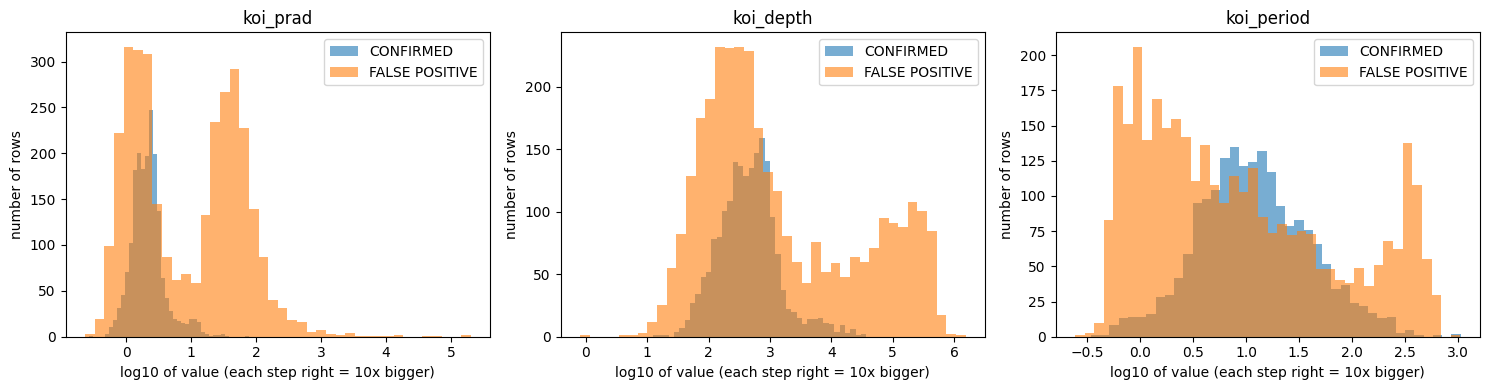

In [18]:
# Stage 1: check whether koi_eccen really is one value in every row
print(train_df["koi_eccen"].value_counts(dropna=False))    # expect 0.0 -> 5115 and NaN -> 190

# Stage 2: draw planets vs false positives for three inputs (training pile only)
import matplotlib.pyplot as plt
import numpy as np

def plot_by_label(df, columns):
    """Draw one histogram per column, CONFIRMED and FALSE POSITIVE overlaid, on a log scale."""
    fig, axes = plt.subplots(1, len(columns), figsize=(5 * len(columns), 4))
    for ax, col in zip(axes, columns):
        for label, color in [("CONFIRMED", "tab:blue"), ("FALSE POSITIVE", "tab:orange")]:
            values = df.loc[df["koi_disposition"] == label, col].dropna()   # this label's values, gaps removed
            values = values[values > 0]                                     # a log needs positive numbers
            ax.hist(np.log10(values), bins=40, alpha=0.6, color=color, label=label)
        ax.set_title(col)
        ax.set_xlabel("log10 of value (each step right = 10x bigger)")
        ax.set_ylabel("number of rows")
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_by_label(train_df, ["koi_prad", "koi_depth", "koi_period"])

In [19]:
# remove koi_eccen, and other waste things from the inputs

# Stage 1: find input columns that hold the same value in every training row
def find_constant_columns(df, columns):
    """Return the columns with at most one distinct value (blank cells are ignored)."""
    return [c for c in columns if df[c].nunique() <= 1]

constant_cols = find_constant_columns(train_df, feature_cols)
print("Constant columns:", constant_cols)          # expect ['koi_eccen'] at least

# Stage 2: remove them from the list of model inputs
feature_cols = [c for c in feature_cols if c not in constant_cols]
print("Input columns now:", len(feature_cols))     # expect 35 if only koi_eccen was found

Constant columns: ['koi_eccen', 'koi_ldm_coeff4', 'koi_ldm_coeff3']
Input columns now: 33


### ----- DONE WITH DATA UNDERSTANDING, MODIFYING AND SPLITTING --------------------------------------

In [20]:
# downloading lightcurve files of some trials stars first

# Stage 1: define the picker
def pick_trial_stars(df, n_each, seed):
    """Pick n_each single-object stars per label from a table, using a fixed seed."""
    counts = df["kepid"].value_counts()                 # how many rows each star has
    single_ids = counts[counts == 1].index              # stars that have exactly one row
    single = df[df["kepid"].isin(single_ids)]           # keep only those stars' rows

    picks = []
    for label in ["CONFIRMED", "FALSE POSITIVE"]:       # do the same thing once per label
        group = single[single["koi_disposition"] == label]
        picks.append(group.sample(n=n_each, random_state=seed))   # random, but repeatable
    return pd.concat(picks)                             # glue the two small tables together

# Stage 2: pick 3 planets and 3 false positives from the TRAINING pile only
trial_stars = pick_trial_stars(train_df, n_each=3, seed=SEED)

# Stage 3: look at them
display(trial_stars[["kepid", "kepoi_name", "koi_disposition",
                     "koi_period", "koi_depth", "koi_model_snr"]])

,kepid,kepoi_name,koi_disposition,koi_period,koi_depth,koi_model_snr
1222,5183357,K01669.01,CONFIRMED,61.037359,437.5,40.2
1593,2987027,K00197.01,CONFIRMED,17.276297,10458.0,871.4
2160,5514383,K00257.01,CONFIRMED,6.883413,487.4,35.4
3696,8254882,K04164.01,FALSE POSITIVE,0.925659,30.0,11.2
9265,10471204,K08018.01,FALSE POSITIVE,0.933716,61.3,10.3
8190,6207053,K06675.01,FALSE POSITIVE,0.604755,334.5,40.3


In [21]:
# Stage 1: set up the settings and the download function
import time
import lightkurve as lk
from pathlib import Path

QUARTERS = [1, 2, 3, 4]                 # the ~3-month chunks of Kepler data we use
LC_DIR = "/content/lc_cache"            # folder in Colab where the files get saved

def download_star(kepid, quarters, folder):
    """Download one star's Kepler light curves and return (curves or None, a summary dictionary)."""
    start = time.time()                                       # start the stopwatch
    info = {"kepid": int(kepid), "files_found": 0, "points": 0, "seconds": None, "status": ""}
    lcs = None
    try:                                                      # try this; if it crashes, jump to 'except'
        found = lk.search_lightcurve(f"KIC {kepid}", author="Kepler",
                                     cadence="long", quarter=quarters)
        info["files_found"] = len(found)                      # how many quarter-files exist
        if len(found) == 0:
            info["status"] = "NO DATA FOUND"
        else:
            lcs = found.download_all(download_dir=folder)     # the actual download
            if lcs is None:
                info["status"] = "DOWNLOAD RETURNED NOTHING"
            else:
                info["points"] = sum(len(lc) for lc in lcs)   # total brightness measurements
                info["status"] = "OK"
    except Exception as err:                                  # something went wrong: note it, keep going
        info["status"] = f"FAILED: {type(err).__name__}: {str(err)[:80]}"
    info["seconds"] = round(time.time() - start, 1)           # stop the stopwatch
    return lcs, info

# Stage 2: try all 6 trial stars, one at a time
light_curves = {}                                             # kepid -> its downloaded curves
report = []                                                   # one summary per star
for kepid in trial_stars["kepid"]:
    lcs, info = download_star(kepid, QUARTERS, LC_DIR)
    light_curves[int(kepid)] = lcs
    report.append(info)
    print(info)                                               # shows progress as we go

# Stage 3: summary table, plus how much space the files take
display(pd.DataFrame(report))

def folder_size_mb(folder):
    """Return the total size of all files inside a folder, in megabytes."""
    files = [f for f in Path(folder).rglob("*") if f.is_file()]
    return len(files), round(sum(f.stat().st_size for f in files) / 1_000_000, 1)

n_files, size_mb = folder_size_mb(LC_DIR)
print("Files saved:", n_files, " Total size (MB):", size_mb)

{'kepid': 5183357, 'files_found': 4, 'points': 13957, 'seconds': 10.3, 'status': 'OK'}
{'kepid': 2987027, 'files_found': 4, 'points': 13957, 'seconds': 8.5, 'status': 'OK'}
{'kepid': 5514383, 'files_found': 4, 'points': 13957, 'seconds': 9.0, 'status': 'OK'}
{'kepid': 8254882, 'files_found': 4, 'points': 13957, 'seconds': 8.5, 'status': 'OK'}
{'kepid': 10471204, 'files_found': 4, 'points': 13957, 'seconds': 8.4, 'status': 'OK'}
{'kepid': 6207053, 'files_found': 4, 'points': 13957, 'seconds': 8.8, 'status': 'OK'}


,kepid,files_found,points,seconds,status
0,5183357,4,13957,10.3,OK
1,2987027,4,13957,8.5,OK
2,5514383,4,13957,9.0,OK
3,8254882,4,13957,8.5,OK
4,10471204,4,13957,8.4,OK
5,6207053,4,13957,8.8,OK


Files saved: 24  Total size (MB): 9.6


### FINAL FINISHING WORK BEGIN

In [22]:
# ===== CELL 1: train three models and compare them on the VALIDATION pile =====

# Stage 1: imports
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

# Stage 2: split each pile into inputs (X) and answers (y); y = 1 means planet, 0 means false positive
def split_xy(df):
    """Return the model inputs X and the 0/1 answers y (1 = CONFIRMED planet) for one pile."""
    X = df[feature_cols]
    y = (df[label_col] == "CONFIRMED").astype(int)
    return X, y

X_train, y_train = split_xy(train_df)
X_val, y_val = split_xy(val_df)
X_test, y_test = split_xy(test_df)        # made now, but NOT used until Cell 2

# Stage 3: the three models we compare
models = {
    "Always says false positive": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(
        SimpleImputer(strategy="median"),                         # fill blanks with the middle value
        QuantileTransformer(output_distribution="normal", random_state=SEED),   # tame huge outliers
        LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=SEED),     # handles blanks by itself
}

# Stage 4: a function that scores a fitted model on one pile
def evaluate(model, X, y):
    """Return accuracy, precision, recall, F1 and AUC of a fitted model on one pile."""
    pred = model.predict(X)                       # hard answers: 0 or 1
    prob = model.predict_proba(X)[:, 1]           # how sure the model is that it is a planet
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "auc": roc_auc_score(y, prob),
    }

# Stage 5: train every model on the TRAIN pile, score it on the VALIDATION pile
val_rows = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    val_rows[name] = evaluate(model, X_val, y_val)
val_scores = pd.DataFrame(val_rows).T.round(3)
display(val_scores)

,accuracy,precision,recall,f1,auc
Always says false positive,0.637,0.000,0.000,0.000,0.500
Logistic regression,0.851,0.747,0.891,0.812,0.930
Gradient boosting,0.939,0.919,0.912,0.916,0.985


Chosen model: Gradient boosting

Top 8 inputs (bigger = the model needs it more):
koi_max_mult_ev     0.0293
koi_prad            0.0292
koi_dor             0.0215
koi_max_sngle_ev    0.0135
koi_ror             0.0106
koi_model_snr       0.0082
koi_smet            0.0053
ra                  0.0035
dtype: float64 

TEST scores: {'accuracy': 0.936, 'precision': 0.919, 'recall': 0.911, 'f1': 0.915, 'auc': 0.981}
Lazy model accuracy on test (the floor): 0.621


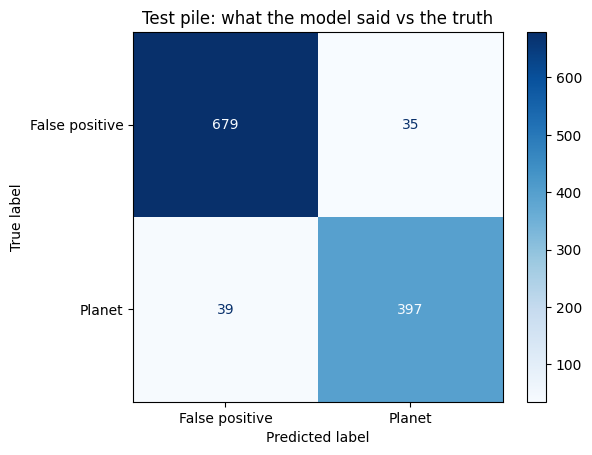

Planets caught: 397 of 436 | False alarms let through as planets: 35 of 714
Saved: results.json, planet_model.joblib, confusion_matrix.png


In [23]:
# ===== CELL 2: pick the winner, then the final exam on the TEST pile =====

# Stage 1: imports
import json, joblib
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Stage 2: pick the winner on VALIDATION (highest AUC among the two real models)
real_models = val_scores.drop(index="Always says false positive")
best_name = real_models["auc"].idxmax()
print("Chosen model:", best_name)

# Stage 3: which inputs does the chosen model lean on? (measured on VALIDATION, not test)
imp = permutation_importance(models[best_name], X_val, y_val,
                             scoring="roc_auc", n_repeats=5, random_state=SEED)
importance = pd.Series(imp.importances_mean, index=feature_cols).sort_values(ascending=False)
print("\nTop 8 inputs (bigger = the model needs it more):")
print(importance.head(8).round(4), "\n")

# Stage 4: retrain a fresh copy of the winner on TRAIN + VALIDATION together
X_final = pd.concat([X_train, X_val])
y_final = pd.concat([y_train, y_val])
final_model = clone(models[best_name]).fit(X_final, y_final)

# Stage 5: score on the TEST pile, for the first and only time
test_scores = {k: round(float(v), 3) for k, v in evaluate(final_model, X_test, y_test).items()}
lazy_accuracy = round(float(1 - y_test.mean()), 3)    # accuracy of always answering "false positive"
print("TEST scores:", test_scores)
print("Lazy model accuracy on test (the floor):", lazy_accuracy)

# Stage 6: confusion matrix picture, saved as a file
test_pred = final_model.predict(X_test)
cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["False positive", "Planet"]).plot(cmap="Blues")
plt.title("Test pile: what the model said vs the truth")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Planets caught: {tp} of {tp + fn} | False alarms let through as planets: {fp} of {fp + tn}")

# Stage 7: save the results and the trained model
results = {
    "best_model": best_name,
    "validation": val_scores.to_dict(orient="index"),
    "test": test_scores,
    "test_lazy_accuracy": lazy_accuracy,
    "test_confusion_matrix": {"true_neg": int(tn), "false_pos": int(fp), "false_neg": int(fn), "true_pos": int(tp)},
    "top_features": importance.head(8).round(4).to_dict(),
    "n_features": len(feature_cols),
    "rows": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
}
with open("results.json", "w") as f:
    json.dump(results, f, indent=2)
joblib.dump({"model": final_model, "features": feature_cols}, "planet_model.joblib")
print("Saved: results.json, planet_model.joblib, confusion_matrix.png")

In [24]:
# ===== CELL 3: write the README automatically, with the real numbers filled in =====

def to_markdown_table(df):
    """Turn a small pandas table into a Markdown table string."""
    header = "| model | " + " | ".join(df.columns) + " |"
    divider = "|---|" + "---|" * len(df.columns)
    lines = [header, divider]
    for name, row in df.iterrows():
        lines.append(f"| {name} | " + " | ".join(str(v) for v in row.values) + " |")
    return "\n".join(lines)

top_feats = "\n".join(f"- `{k}`: {v}" for k, v in results["top_features"].items())
t, cmx, r = results["test"], results["test_confusion_matrix"], results["rows"]

readme = f"""# Planet or Not

A classifier that looks at NASA Kepler "objects of interest" and predicts whether each one is a **confirmed exoplanet** or a **false positive** (something that looked like a planet but was not).

**Scope, stated honestly:** this version uses only the summary numbers in NASA's KOI table. It does **not** use the light curves (the brightness-over-time data). A light-curve neural network was planned but is not part of this version.

## Data
- NASA Exoplanet Archive, Kepler Objects of Interest (cumulative table): 9,564 rows.
- Trained on rows labelled CONFIRMED or FALSE POSITIVE only ({r['train'] + r['val'] + r['test']:,} rows). CANDIDATE rows have no final answer, so they were set aside.

## Avoiding leakage (the main care taken)
- Removed columns that record how NASA decided the label: the disposition score, the Kepler pipeline's own verdict, the four false-positive test flags, vetting comments and dates, and the Kepler name (only given to confirmed planets). On the labelled rows, the pipeline verdict matched the label in 99.9% of cases, so keeping it would have made the task meaningless.
- Also set aside: empty columns, uncertainty columns, pipeline bookkeeping columns, and image-based centroid columns.
- Final model uses {results['n_features']} numeric inputs (orbit period, transit depth and duration, signal-to-noise, estimated object size, star properties and so on).

## Split
- Split **by star** (`kepid`), 70 / 15 / 15, fixed random seed. A star with several objects never appears in more than one pile.
- Rows: train {r['train']:,}, validation {r['val']:,}, test {r['test']:,}.
- The test pile was used once, after the model was chosen on validation.

## Results
Validation pile (used to choose the model):

{to_markdown_table(val_scores)}

Test pile, final model (**{results['best_model']}**, retrained on train + validation):

| accuracy | precision | recall | F1 | AUC |
|---|---|---|---|---|
| {t['accuracy']} | {t['precision']} | {t['recall']} | {t['f1']} | {t['auc']} |

- A model that always answers "false positive" gets **{results['test_lazy_accuracy']}** accuracy on the test pile, so that is the floor to beat.
- Confusion matrix on test: {cmx['true_pos']} planets caught, {cmx['false_neg']} planets missed, {cmx['false_pos']} false positives wrongly called planets, {cmx['true_neg']} false positives correctly rejected. See `confusion_matrix.png`.

Inputs the chosen model relied on most (permutation importance on the validation pile: how much AUC drops when an input is scrambled):
{top_feats}

## Limitations
- In the training-pile histograms, many false positives sit at very large sizes or very deep dips, where almost no planets are, so they are easy to spot. Harder look-alikes, which resemble small planets, are probably where most mistakes happen. This was not analysed separately.
- Only one train / validation / test split was used, so the scores have no error bars.
- No light curves were used, so the model cannot look at the actual shape of the dip.
- Not deployed: there is no web app yet. The saved model file can be loaded for that.
- Labels come from NASA's table, which includes decisions made by automated and human vetting, not independent ground truth.

## What I would do next
- Add light-curve features. A pre-folded Kepler dataset from the AstroNet project (Shallue & Vanderburg, 2018) is available and would avoid downloading raw files.
- Separate error analysis for the hard look-alikes.
- Repeat the split with several seeds to get error bars.

## Files
- `planet_model.joblib`: trained model and its list of input columns
- `results.json`: all scores
- `confusion_matrix.png`: test results picture
"""

with open("README.md", "w") as f:
    f.write(readme)
print(readme)

# Planet or Not

A classifier that looks at NASA Kepler "objects of interest" and predicts whether each one is a **confirmed exoplanet** or a **false positive** (something that looked like a planet but was not).

**Scope, stated honestly:** this version uses only the summary numbers in NASA's KOI table. It does **not** use the light curves (the brightness-over-time data). A light-curve neural network was planned but is not part of this version.

## Data
- NASA Exoplanet Archive, Kepler Objects of Interest (cumulative table): 9,564 rows.
- Trained on rows labelled CONFIRMED or FALSE POSITIVE only (7,587 rows). CANDIDATE rows have no final answer, so they were set aside.

## Avoiding leakage (the main care taken)
- Removed columns that record how NASA decided the label: the disposition score, the Kepler pipeline's own verdict, the four false-positive test flags, vetting comments and dates, and the Kepler name (only given to confirmed planets). On the labelled rows, the pipeline verdict m